# 03 — El modelo de alquiler

**La pregunta.** ¿Cuánto se puede confiar en el alquiler estimado de cada propiedad?

**Por qué importa.** Una propiedad publicada en venta no trae su alquiler: se estima con
un modelo. Los cuatro KPIs dependen de esa estimación, así que todo lo que el trabajo
dice sobre rentabilidad hereda su error. La devolución difirió a esta entrega la
revisión formal del modelo, y la consigna pide compararlo con una referencia razonable
y evaluarlo fuera de muestra.

**Qué se revisa.**

1. ¿El modelo le gana a una regla simple? ¿Algo más complejo le gana a él?
2. ¿Qué paga el mercado de alquiler, según el modelo?
3. ¿La banda de incertidumbre del KPI 4 cubre lo que dice cubrir?
4. ¿El modelo guardado se puede auditar?

**De dónde salen los números.** `src/comparacion_modelos.py` compara los modelos (tarda
unos 4 minutos, por eso este notebook lee su salida); `src/kpis.py` entrena el modelo
vigente y la banda, y los guarda con su metadata en `modelo_alquiler.joblib`.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold

import comparacion_modelos as CM
import eda
import modelo_alquiler as M
import supuestos as S

eda.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

P = "../data/processed"
df = pd.read_csv(f"{P}/dataset_analitico.csv", encoding="utf-8-sig", low_memory=False)
modelo = joblib.load(f"{P}/modelo_alquiler.joblib")
comp = pd.read_csv(f"{P}/comparacion_modelos.csv", encoding="utf-8-sig")
n_alq, n_vta = int((df["operacion"] == "alquiler").sum()), int((df["operacion"] == "venta").sum())
print(f"Alquileres observados: {n_alq:,}. Ventas sin alquiler observado: {n_vta:,} "
      f"({n_vta / n_alq:.1f} por cada alquiler).")

Alquileres observados: 1,348. Ventas sin alquiler observado: 10,749 (8.0 por cada alquiler).


**El problema.** Hay ocho ventas por cada alquiler publicado. El modelo aprende de los
alquileres observados qué paga el mercado por cada característica, y con eso estima el
alquiler de las ventas. Es una predicción transversal: el alquiler de hoy de una
propiedad comparable, no un pronóstico.

El modelo vigente es una regresión Ridge sobre log(alquiler) con 21 predictoras:
superficie, ambientes, baños, dormitorios, antigüedad, barrio, tipo de propiedad y 14
atributos extraídos del texto.

## 1. ¿El modelo le gana a una regla simple, y algo más complejo le gana a él?

Cuatro modelos, todos fuera de muestra con el mismo esquema: validación cruzada de 5
particiones, repetida con tres semillas para ver si las diferencias son señal o ruido.

| Modelo | Por qué está |
|---|---|
| Mediana de barrio × tramo de superficie | La referencia razonable: el alquiler por m² típico de la celda, por la superficie |
| Ridge vigente | El punto de partida |
| Ridge + variables espaciales | Cuánto aportan las distancias del notebook 01 |
| Gradient boosting | Cuánta señal hay en interacciones que un modelo lineal no ve. Mismas variables que el anterior, afinado por validación cruzada interna |

In [2]:
orden = ["mediana barrio x tramo", "ridge", "ridge + espaciales", "boosting"]
tabla = comp.groupby("modelo").agg(r2_medio=("r2_log", "mean"), r2_min=("r2_log", "min"), r2_max=("r2_log", "max"),
                                   error_medio=("error_mediano_pct", "mean"),
                                   error_min=("error_mediano_pct", "min"),
                                   error_max=("error_mediano_pct", "max")).loc[orden]
tabla.style.format({c: "{:.4f}" for c in ["r2_medio", "r2_min", "r2_max"]}
                   | {c: "{:.2f}%" for c in ["error_medio", "error_min", "error_max"]})

,r2_medio,r2_min,r2_max,error_medio,error_min,error_max
modelo,,,,,,
mediana barrio x tramo,0.7505,0.7428,0.7551,15.05%,15.02%,15.08%
ridge,0.8468,0.8459,0.8480,11.42%,11.20%,11.70%
ridge + espaciales,0.8466,0.8457,0.8480,11.56%,11.40%,11.80%
boosting,0.8442,0.8418,0.8485,11.41%,11.33%,11.54%


### Gráfico 06 — ¿Qué modelo estima mejor el alquiler fuera de muestra?

R² en logaritmo y error relativo mediano de cada modelo. El punto es el promedio de las
tres semillas; la línea, el rango entre la peor y la mejor.

guardado: ../graficos\06_comparacion_modelos.png


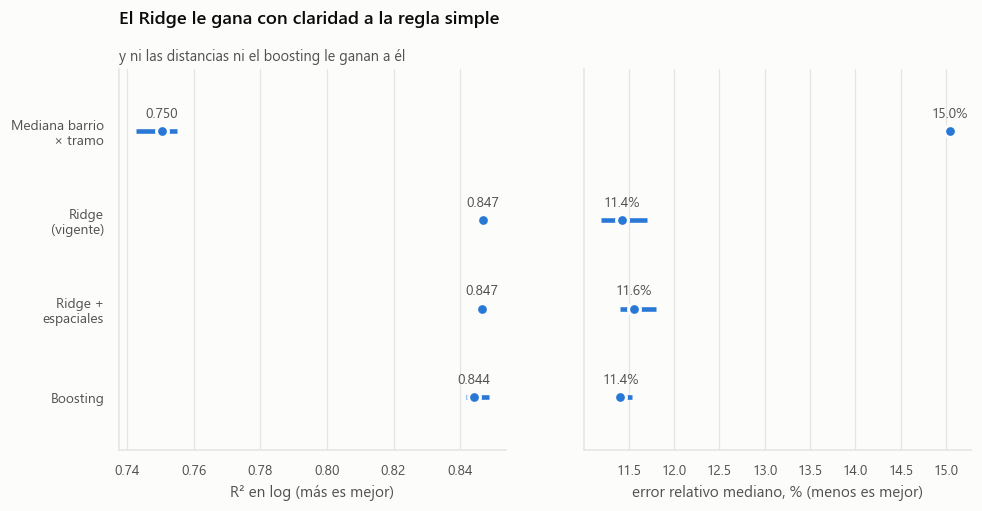

In [3]:
nombres = ["Mediana barrio\n× tramo", "Ridge\n(vigente)", "Ridge +\nespaciales", "Boosting"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
yy = np.arange(len(orden))[::-1]
for ax, (col, etiqueta, fmt) in zip(axes, [("r2", "R² en log (más es mejor)", "{:.3f}"),
                                           ("error", "error relativo mediano, % (menos es mejor)", "{:.1f}%")]):
    ax.hlines(yy, tabla[f"{col}_min"], tabla[f"{col}_max"], color=eda.SERIE_1, linewidth=3)
    ax.scatter(tabla[f"{col}_medio"], yy, s=60, color=eda.SERIE_1, edgecolor=eda.SUPERFICIE, linewidth=2, zorder=3)
    for y_, val in zip(yy, tabla[f"{col}_medio"]):
        ax.annotate(fmt.format(val), (val, y_), xytext=(0, 9), textcoords="offset points",
                    ha="center", fontsize=9, color=eda.TINTA_2)
    ax.set_xlabel(etiqueta)
    eda.sin_grilla_y(ax)
axes[0].set_yticks(yy, nombres)
axes[0].set_ylim(-0.6, len(orden) - 0.3)
fig.suptitle("")
eda.titulo(axes[0], "El Ridge le gana con claridad a la regla simple",
           "y ni las distancias ni el boosting le ganan a él")
eda.guardar(fig, 6, "comparacion_modelos")
plt.show()

**Lectura.** El Ridge le gana a la referencia con margen: casi diez puntos más de R² y casi
cuatro menos de error mediano (11,42% contra 15,05%). Las dos alternativas no se despegan:
las variables espaciales no agregan nada, y el boosting afinado empata dentro del rango
de las semillas. Es coherente con el notebook 01: la accesibilidad ya está en el barrio,
que el modelo tiene como predictora.

In [4]:
tramos = [f"error_{t}_pct" for t in M.LAB_SUP]
por_tramo = comp.groupby("modelo")[tramos].mean().loc[orden]
por_tramo.columns = [f"{t} m2" for t in M.LAB_SUP]
por_tramo.style.format("{:.1f}%")

,<35 m2,35-50 m2,50-70 m2,70-100 m2,100+ m2
modelo,,,,,
mediana barrio x tramo,12.5%,12.3%,19.6%,20.4%,22.7%
ridge,11.1%,9.6%,12.3%,15.6%,17.0%
ridge + espaciales,10.9%,9.6%,12.4%,15.4%,17.1%
boosting,9.4%,9.6%,13.6%,16.4%,19.2%


**Por tramo de superficie.** Todos los modelos se equivocan más en las unidades
grandes. El boosting gana en monoambientes y pierde en las de más de 70 m², que son
casi la mitad de las ventas. Ningún tramo cambia la conclusión.

## 2. La decisión

El criterio se declaró antes de mirar el resultado (`supuestos.MEJORA_MINIMA_R2`): una
alternativa reemplaza al Ridge solo si mejora el R² en al menos 0,01 en **todas** las
semillas. La consigna lo dice así: un método simple y bien justificado es preferible a
una técnica avanzada sin una pregunta clara.

In [5]:
r2 = comp.pivot(index="semilla", columns="modelo", values="r2_log")
dif = r2[["ridge + espaciales", "boosting"]].sub(r2["ridge"], axis=0)
display(dif.style.format("{:+.4f}"))
cumple = (dif >= S.MEJORA_MINIMA_R2).all()
print("Cumplen el criterio:", list(cumple[cumple].index) or "ninguna. El Ridge sigue siendo el modelo vigente.")

modelo,ridge + espaciales,boosting
semilla,,
7,-0.0004,+0.0019
42,+0.0000,-0.0057
2026,-0.0002,-0.0041


Cumplen el criterio: ninguna. El Ridge sigue siendo el modelo vigente.


**Lectura.** Ninguna alternativa cumple el criterio, así que el modelo no cambia y los
KPIs tampoco. El Ridge se queda por una razón más que el empate: sus coeficientes se
leen directamente como cuánto paga el mercado por cada característica, y esa lectura
es parte del producto para el inversor.

**Qué pasa con las variables espaciales.** Son las seis distancias del notebook 01: al
subte, al tren, al Metrobús, a la red más cercana de las tres, y a la plaza y al parque
más cercanos (estas dos últimas no son de transporte). Se probaron **solo** en la
variante "Ridge + espaciales" de esta comparación: el modelo vigente nunca las incluyó y
sigue con las mismas 21 predictoras de la 2da entrega. **No se eliminaron del trabajo**:
siguen como columnas de `dataset_analitico.csv`, se usan para H2 en el notebook 01 y
quedan disponibles para el tablero. No mejoran la estimación del alquiler porque el
modelo ya tiene el barrio como predictora, y la accesibilidad viaja casi entera con el
barrio: dentro del mismo barrio, la distancia a la red agrega 0,0018 de R² al precio del
m² (notebook 01, sección 5).

## 3. ¿Qué paga el mercado de alquiler?

### Gráfico 07 — ¿Cuánto más se alquila una propiedad que tiene cada atributo?

Variación del alquiler estimado por la presencia de cada atributo extraído del texto,
a igualdad de las otras características.

guardado: ../graficos\07_coeficientes_modelo.png


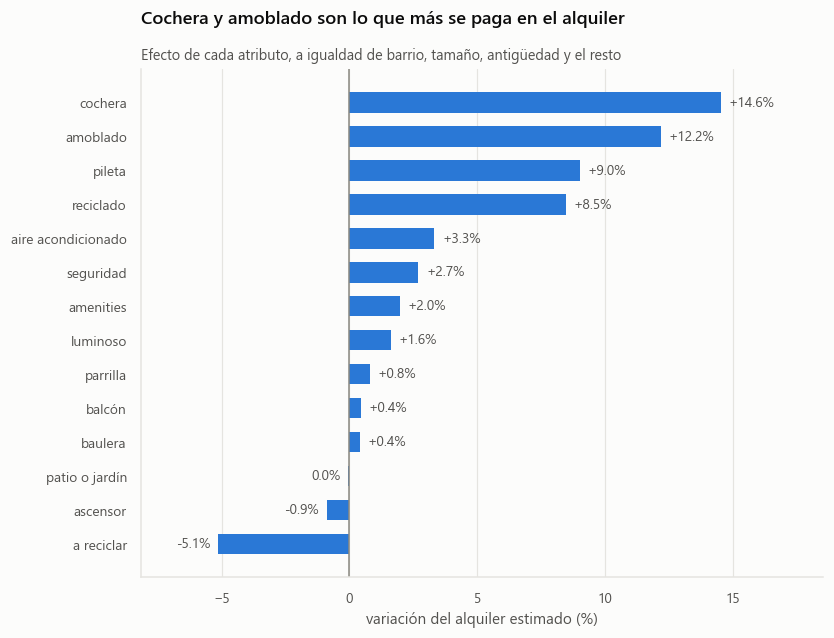

In [6]:
pre, coef = modelo["pipeline"].named_steps["pre"], modelo["pipeline"].named_steps["mod"].coef_
efecto = pd.Series(np.expm1(coef) * 100, index=[n.split("__")[-1] for n in pre.get_feature_names_out()])
efecto = efecto[M.DUMMIES].sort_values()
etiquetas = {"cochera_txt": "cochera", "aire_acondicionado": "aire acondicionado", "patio_jardin": "patio o jardín",
             "a_reciclar": "a reciclar", "baulera": "baulera", "balcon": "balcón"}

fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(len(efecto))
ax.barh(yy, efecto.values, height=0.6, color=eda.SERIE_1)
ax.axvline(0, color=eda.TINTA_3, linewidth=1)
for y_, val in zip(yy, efecto.values):
    texto = f"{val:+.1f}%" if abs(val) >= 0.05 else "0.0%"
    ax.text(val + (0.3 if val >= 0 else -0.3), y_, texto, va="center",
            ha="left" if val >= 0 else "right", fontsize=9, color=eda.TINTA_2)
ax.set_yticks(yy, [etiquetas.get(k, k) for k in efecto.index])
ax.set_xlabel("variación del alquiler estimado (%)")
ax.set_xlim(efecto.min() - 3, efecto.max() + 4)
eda.sin_grilla_y(ax)
eda.titulo(ax, "Cochera y amoblado son lo que más se paga en el alquiler",
           "Efecto de cada atributo, a igualdad de barrio, tamaño, antigüedad y el resto")
eda.guardar(fig, 7, "coeficientes_modelo")
plt.show()

**Lectura.** La cochera y el amoblado suben el alquiler más de 10%, y una unidad
reciclada se alquila 8,5% más mientras que una a reciclar, 5% menos. Son estos efectos
los que alimentan la estimación del alquiler post-refacción del notebook 02. Los
amenities, en cambio, suman solo 2%, y el ascensor y el patio, nada.

## 4. La banda de incertidumbre del KPI 4

Hasta la 2da entrega, la banda de cada propiedad era su estimación más y menos el
**error mediano de su tramo de superficie**. Todas las propiedades del mismo tamaño
tenían la misma banda, y como el error usado es una mediana, la banda dejaba afuera a la
mitad de los alquileres por construcción.

Ahora la banda son los **percentiles 10 y 90** del alquiler de cada propiedad, en dos
pasos:

1. una **regresión cuantílica** con las mismas variables que el Ridge: la banda cambia
   con las características de cada propiedad;
2. una **calibración conformal por grupo de evidencia** (cuántos alquileres observados
   tiene el barrio), para que cada grupo cubra el 80% fuera de muestra.

**Esto no mejora la estimación puntual del alquiler, que no cambia.** Mejora lo que se
sabe sobre cuánta confianza merece.

In [7]:
alq = M.preparar(pd.read_csv(f"{P}/dataset_espacial.csv", encoding="utf-8-sig", low_memory=False))
alq = alq[alq["operacion"] == "alquiler"].dropna(subset=["alquiler_usd_mes", "sup_total_m2", "barrio"]).reset_index(drop=True)
anterior = CM.cobertura_banda_anterior(alq, np.log(alq["alquiler_usd_mes"].values),
                                       KFold(M.N_FOLDS, shuffle=True, random_state=M.SEMILLA_CV))
b = modelo["banda"]
print(f"Alquileres observados dentro de la banda, fuera de muestra (objetivo {M.COBERTURA_OBJETIVO:.0%}):")
print(f"    2da entrega, estimacion +- error mediano del tramo : {anterior:.1%}")
print(f"    regresion cuantilica sola                         : {b['cobertura_cruda']:.1%}")
print(f"    regresion cuantilica calibrada                    : {b['cobertura_calibrada']:.1%}")

Alquileres observados dentro de la banda, fuera de muestra (objetivo 80%):
    2da entrega, estimacion +- error mediano del tramo : 50.1%
    regresion cuantilica sola                         : 77.5%
    regresion cuantilica calibrada                    : 81.6%


### Gráfico 08 — ¿La banda cubre lo que dice cubrir, también donde hay pocos datos?

Porcentaje de los alquileres observados que cae dentro de su banda fuera de muestra,
por grupo de evidencia del barrio. La cobertura calibrada se mide con validación
anidada: el ajuste de cada partición se calcula sin ver los alquileres que evalúa.

guardado: ../graficos\08_cobertura_banda.png


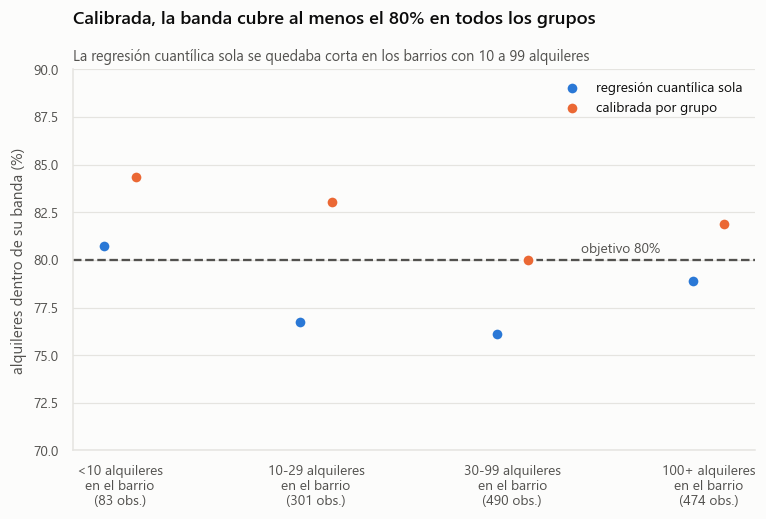

In [8]:
grupos = M.GRUPOS_EVIDENCIA
cruda = [b["cobertura_cruda_por_grupo"][g] * 100 for g in grupos]
calib = [b["cobertura_calibrada_por_grupo"][g] * 100 for g in grupos]
n = [b["alquileres_por_grupo"][g] for g in grupos]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(grupos))
ax.axhline(M.COBERTURA_OBJETIVO * 100, color=eda.TINTA_2, linewidth=1.5, linestyle="--")
# Entre el tercer y el cuarto grupo no hay puntos: ahi la etiqueta no tapa nada.
ax.text(2.35, M.COBERTURA_OBJETIVO * 100 + 0.4, "objetivo 80%", fontsize=9, color=eda.TINTA_2)
ax.scatter(x - 0.08, cruda, s=70, color=eda.SERIE_1, label="regresión cuantílica sola",
           edgecolor=eda.SUPERFICIE, linewidth=2, zorder=3)
ax.scatter(x + 0.08, calib, s=70, color=eda.SERIE_2, label="calibrada por grupo",
           edgecolor=eda.SUPERFICIE, linewidth=2, zorder=3)
ax.set_xticks(x, [f"{g} alquileres\nen el barrio\n({k} obs.)" for g, k in zip(grupos, n)])
ax.set_ylim(70, 90)
ax.set_ylabel("alquileres dentro de su banda (%)")
ax.legend(loc="upper right")
eda.titulo(ax, "Calibrada, la banda cubre al menos el 80% en todos los grupos",
           "La regresión cuantílica sola se quedaba corta en los barrios con 10 a 99 alquileres")
eda.guardar(fig, 8, "cobertura_banda")
plt.show()

**Lectura.** La regresión cuantílica sola cubría 77,5%: un poco menos de lo que
promete, y con el faltante concentrado en los barrios con 10 a 99 alquileres. Calibrada,
cubre entre 80% y 84% en todos los grupos. La banda anterior cubría la mitad.

Un resultado que no era el esperado: los barrios con **menos** de 10 alquileres no se
predicen peor que el resto fuera de muestra, así que su banda no necesita ser mucho más
ancha. El ancho de la banda depende más del tamaño de la propiedad que de cuántos datos
hay en su barrio.

In [9]:
v = df[(df["estimacion_confiable"] == 1) & df["rent_bruta_pct"].notna()]
ancho = v["rent_bruta_max"] - v["rent_bruta_min"]
tramo = pd.cut(v["sup_total_m2"], M.BINS_SUP, labels=[f"{t} m2" for t in M.LAB_SUP])
display(ancho.groupby(tramo, observed=True).median().rename("ancho mediano de la banda (pp)").to_frame().T)
med = v["rent_bruta_pct"].median()
contiene = ((v["rent_bruta_min"] <= med) & (v["rent_bruta_max"] >= med)).mean()
print(f"Banda mediana de la bruta: {v['rent_bruta_min'].median():.2f}% a {v['rent_bruta_max'].median():.2f}% "
      f"(ancho {ancho.median():.2f} pp)")
print(f"Propiedades cuya banda contiene la bruta mediana del mercado: {contiene:.1%}")

sup_total_m2,<35 m2,35-50 m2,50-70 m2,70-100 m2,100+ m2
ancho mediano de la banda (pp),2.61,2.92,3.23,3.61,4.92


Banda mediana de la bruta: 5.37% a 8.85% (ancho 3.45 pp)
Propiedades cuya banda contiene la bruta mediana del mercado: 67.2%


**Lectura para la decisión.** La banda honesta es más ancha que la anterior: unos 3,5
puntos de rentabilidad bruta en la propiedad mediana, y casi 5 en las de más de 100 m².
Dos de cada tres propiedades tienen una banda que contiene la rentabilidad mediana del
mercado: para ellas, la diferencia contra el promedio no se distingue del error de
estimación. El criterio de P2 (recomendar una propiedad sobre otra solo si sus bandas
no se superponen) va a ser más exigente con esta banda, y eso es lo correcto: la
anterior prometía una precisión que no tenía.

## 5. El modelo guardado

La devolución pidió poder auditar el `.joblib`. Además del pipeline, ahora guarda con
qué se entrenó, cuándo, sobre qué datos y cuánto rinde fuera de muestra. El hash
permite comprobar que corresponde a este dataset (`src/test_modelo.py` lo verifica).

In [10]:
meta = modelo["metadata"]
for k in ["sklearn", "entrenado", "entrada", "n_entrenamiento", "hash_entrenamiento_sha256"]:
    print(f"{k:<28} {meta[k]}")
print(f"{'predictoras':<28} {sum(len(x) for x in meta['predictoras'].values())} "
      f"({', '.join(f'{len(x)} {k}' for k, x in meta['predictoras'].items())})")
print(f"{'validacion':<28} {meta['metricas_validacion']['esquema']}: R2 {meta['metricas_validacion']['r2_log']}, "
      f"error mediano {meta['metricas_validacion']['error_relativo_mediano']:.1%}")
print(f"{'cobertura de la banda':<28} {meta['cobertura_banda']}")

sklearn                      1.9.0
entrenado                    2026-10-29T16:52:40
entrada                      data/processed/dataset_espacial.csv
n_entrenamiento              1348
hash_entrenamiento_sha256    83f3a4a386b7ccc1f992db9300cf6c459a87443f80a32227acadd7d8f53ab0f8
predictoras                  21 (5 numericas, 2 categoricas, 14 dummies)
validacion                   KFold(5, shuffle=True, random_state=42): R2 0.848, error mediano 11.2%
cobertura de la banda        {'objetivo': 0.8, 'cruda': 0.7752, 'calibrada': 0.816}


## Resumen del notebook

1. **El modelo le gana a la referencia con claridad**: R² de 0,847 contra 0,751, y error
   mediano de 11,42% contra 15,05%, fuera de muestra y en tres particiones.
2. **Ninguna alternativa lo mejora**: las variables espaciales no agregan y el boosting
   empata. El Ridge se queda, con su lectura de qué paga el mercado.
3. **La banda del KPI 4 ahora cubre lo que dice**: 81,6% fuera de muestra contra un
   objetivo de 80%, en todos los grupos de evidencia. La anterior cubría 50%.
4. **Con la banda honesta, dos de cada tres propiedades no se distinguen del promedio
   del mercado**. Es el insumo del criterio de decisión del notebook 06.
5. **El modelo guardado es auditable**: versión, fecha, hash de los datos, predictoras y
   métricas.

**Lo que este notebook no hace:** no cambia la estimación puntual del alquiler ni los
KPIs 1 a 3, que siguen siendo los del notebook 02.